# Verification and Validation for Functional Safety

**Module 03 · Functional Safety (ISO 26262)** · Notebook 5 of 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/03_Functional_Safety_ISO26262/05_verification_and_validation.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~50 min | [02 HARA](02_hara.ipynb), [03 FMEA and FMEDA](03_fmea_and_fmeda.ipynb) | ISO 26262-4:2018, ISO 26262-6:2018, ISO 26262-2:2018 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Distinguish verification, safety validation and confirmation measures in ISO 26262
2. Select software unit verification methods and structural-coverage metrics per ASIL (ISO 26262-6:2018 Tables 7 and 9)
3. Build a requirements-to-test traceability matrix and detect tests that are weaker than their requirement
4. Separate ISO 26262 safety requirements from SOTIF / ISO/PAS 8800 acceptance criteria for ML components
5. Quantify a recall claim statistically (zero-failure bound) and interpret fault-injection findings against the FTTI

## 1. V-model, verification and validation

### Where verification happens

```
Item definition & HARA  ............................................  Safety validation (ISO 26262-4 cl. 8)
   Functional / technical safety concept  ......................  Item & system integration testing (ISO 26262-4)
      SW architectural design  ...............................  SW integration & verification (ISO 26262-6 cl. 10)
         SW unit design  ...................................  SW unit verification (ISO 26262-6 cl. 9)
                         \_______ Implementation _______/
```

### Verification, safety validation and confirmation measures

| Aspect | Verification | Safety validation | Confirmation measures |
|---|---|---|---|
| Question | Does the work product fulfil its specified requirements? | Are the safety goals achieved at vehicle level, and are the safety concepts appropriate? | Are the work products, the process and the achieved functional safety adequate? |
| Reference | The requirements and design specification of that level | Safety goals, functional and technical safety concepts | ISO 26262 itself, the safety plan |
| Methods | Reviews, analyses (static, semi-formal, formal), simulation, testing, fault injection | Vehicle-level tests (including fault injection), long-term and user tests, reviews of analyses | Confirmation reviews, functional-safety audit, functional-safety assessment |
| Where | Throughout ISO 26262-3 to -6; ISO 26262-8 clause 9 | ISO 26262-4 clause 8 | ISO 26262-2 clause 6 (Table 1): independence I0–I3 rising with ASIL |

"Process compliance" is the subject of the functional-safety **audit**, not of verification.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Dict, Optional
from enum import Enum
from scipy import stats
from IPython.display import display

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 100})
print("V&V tools loaded.")

V&V tools loaded.


## 2. Verification methods per ASIL

ISO 26262-6:2018 marks each method per ASIL as **++** (highly recommended), **+** (recommended) or **o** (no recommendation for or against its use). There is no "strongly recommended" level and no QM column: QM software is handled by the quality-management system.

- **Table 7**: methods for software unit verification (reviews, analyses and dynamic tests; the dynamic tests are shown below)
- **Table 9**: structural coverage metrics at the software unit level
- Software integration uses Tables 10 and 12; the latter covers function and call coverage at the architectural level

The values below were transcribed from secondary sources; check them against your licensed copy of ISO 26262-6:2018.

In [2]:
class Rec(Enum):
    HR = "++"    # highly recommended
    R = "+"      # recommended
    NONE = "o"   # no recommendation for or against

ASILS = ["A", "B", "C", "D"]
HR, R = Rec.HR, Rec.R

# ISO 26262-6:2018 Table 7 (excerpt: dynamic test methods for software unit verification)
UNIT_VERIFICATION_METHODS = {
    "Requirements-based test": [HR, HR, HR, HR],
    "Interface test": [HR, HR, HR, HR],
    "Fault injection test": [R, R, R, HR],
    "Resource usage evaluation": [R, R, R, HR],
    "Back-to-back comparison test (model vs code, if applicable)": [R, R, HR, HR],
}
# ISO 26262-6:2018 Table 9: structural coverage metrics at the software unit level
COVERAGE_METRICS = {
    "Statement coverage": [HR, HR, R, R],
    "Branch coverage": [R, HR, HR, HR],
    "MC/DC": [R, R, R, HR],
}


def method_level(table: dict, method: str, asil: str) -> Rec:
    """Recommendation level; accepts decomposed ASILs such as 'B(D)' (methods follow the decomposed ASIL)."""
    letter = asil.strip()[0].upper()
    if letter not in ASILS:
        raise ValueError(f"no method table entry for {asil!r} (QM is outside the ISO 26262 tables)")
    return table[method][ASILS.index(letter)]


def show_table(table: dict, title: str):
    print(title)
    print("=" * 92)
    print(f"{'Method':<62}" + "".join(f"{a:^7}" for a in ASILS))
    print("-" * 92)
    for method, recs in table.items():
        print(f"{method:<62}" + "".join(f"{r.value:^7}" for r in recs))
    print("Legend: ++ highly recommended, + recommended, o no recommendation for or against\n")

show_table(UNIT_VERIFICATION_METHODS, "ISO 26262-6:2018 Table 7 (excerpt): software unit verification")
show_table(COVERAGE_METRICS, "ISO 26262-6:2018 Table 9: structural coverage at software unit level")
print("Highly recommended at ASIL B(D):",
      [m for m in UNIT_VERIFICATION_METHODS if method_level(UNIT_VERIFICATION_METHODS, m, "B(D)") is HR])

ISO 26262-6:2018 Table 7 (excerpt): software unit verification
Method                                                           A      B      C      D   
--------------------------------------------------------------------------------------------
Requirements-based test                                         ++     ++     ++     ++   
Interface test                                                  ++     ++     ++     ++   
Fault injection test                                             +      +      +     ++   
Resource usage evaluation                                        +      +      +     ++   
Back-to-back comparison test (model vs code, if applicable)      +      +     ++     ++   
Legend: ++ highly recommended, + recommended, o no recommendation for or against

ISO 26262-6:2018 Table 9: structural coverage at software unit level
Method                                                           A      B      C      D   
--------------------------------------------------------

## 3. Requirements and test cases

For an AI-based perception function, two kinds of requirements have to be verified, and they must not be mixed up:

| Kind | Example | Integrity attribute | Standard |
|---|---|---|---|
| **Safety requirements** against E/E faults | "Detect camera frame loss within 100 ms" | ASIL (here B, B(D) or D) | ISO 26262 |
| **Acceptance criteria** for the nominal performance of the ML function | "Pedestrian recall ≥ 99 % with 95 % confidence in scenario class X" | none: there is no ASIL for recall | ISO 21448 / ISO/PAS 8800 |

Labelling an ML performance metric with an ASIL is a category error. An ASIL grades the rigour of measures against systematic and random faults; it cannot make a recall target come true. A requirement such as "confidence shall drop by 20 % in rain" is not a safety property at all, since lower confidence is not safer in itself, so it is not used below.

Each requirement and test carries a **metric, comparison and threshold**. This lets the notebook check automatically that a test's acceptance criterion is **at least as strict** as the requirement it claims to verify.

In [3]:
@dataclass
class Requirement:
    id: str
    description: str
    integrity: str          # "ASIL B", "ASIL B(D)", ... or "SOTIF/8800 AC"
    source: str             # safety goal or SOTIF acceptance criterion it derives from
    metric: str
    op: str                 # ">=" or "<="
    threshold: float


@dataclass
class TestCase:
    id: str
    name: str
    requirement_id: str
    metric: str
    op: str
    threshold: float        # the test's own acceptance criterion
    test_type: str          # "unit", "integration", "system", "vehicle"
    observed: Optional[float] = None   # None = not run
    note: str = ""

    @property
    def status(self) -> str:
        if self.observed is None:
            return "not_run"
        ok = self.observed >= self.threshold if self.op == ">=" else self.observed <= self.threshold
        return "pass" if ok else "fail"


def is_weaker(tc: TestCase, req: Requirement) -> bool:
    """True if the test's acceptance criterion is less strict than the requirement."""
    if tc.metric != req.metric or tc.op != req.op:
        return True
    return tc.threshold < req.threshold if req.op == ">=" else tc.threshold > req.threshold


@dataclass
class TestSuite:
    name: str
    requirements: List[Requirement] = field(default_factory=list)
    test_cases: List[TestCase] = field(default_factory=list)

    def req(self, rid) -> Optional[Requirement]:
        return next((r for r in self.requirements if r.id == rid), None)

    def consistency_findings(self) -> List[str]:
        out = []
        for tc in self.test_cases:
            r = self.req(tc.requirement_id)
            if r is None:
                out.append(f"{tc.id}: traces to unknown requirement {tc.requirement_id}")
            elif is_weaker(tc, r):
                out.append(f"{tc.id}: criterion '{tc.metric} {tc.op} {tc.threshold}' is weaker than "
                           f"{r.id} '{r.metric} {r.op} {r.threshold}' -> cannot count as verification")
        return out

    def valid_tests_for(self, r: Requirement) -> List[TestCase]:
        return [tc for tc in self.test_cases if tc.requirement_id == r.id and not is_weaker(tc, r)]

    def traceability_matrix(self) -> pd.DataFrame:
        rows = []
        for r in self.requirements:
            tests = self.valid_tests_for(r)
            if not tests:
                verdict = "NOT COVERED"
            elif all(t.status == "pass" for t in tests):
                verdict = "verified"
            elif any(t.status == "fail" for t in tests):
                verdict = "failed"
            else:
                verdict = "open (not run)"
            rows.append({"Requirement": r.id, "Integrity": r.integrity, "Source": r.source,
                         "Tests": ", ".join(t.id for t in tests) or "-", "Status": verdict})
        return pd.DataFrame(rows)

    def coverage_summary(self) -> Dict:
        req_ids = {r.id for r in self.requirements}
        covered = {r.id for r in self.requirements if self.valid_tests_for(r)}
        status = pd.Series([t.status for t in self.test_cases]).value_counts()
        n = len(self.test_cases)
        return {"total_requirements": len(req_ids), "covered_requirements": len(covered),
                "requirement_coverage": 100 * len(covered) / len(req_ids) if req_ids else 0.0,
                "total_tests": n, **{k: int(status.get(k, 0)) for k in ("pass", "fail", "not_run")},
                "pass_rate_executed": 100 * status.get("pass", 0) / max(1, n - status.get("not_run", 0))}

## 4. Example: AEB perception channel

The requirements derive from the AEB safety goals of [Notebook 02](02_hara.ipynb) (SG-01 [ASIL D], SG-02 [ASIL B]) and from SOTIF acceptance criteria.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

In [4]:
suite = TestSuite("AEB perception channel verification")
suite.requirements = [
    Requirement("TSR-01", "Detect loss of camera frames and request the AEB-unavailable state", "ASIL B", "SG-02",
                "frame_loss_detection_ms", "<=", 100),
    Requirement("TSR-02", "Plausibility channel blocks an unconfirmed deceleration request", "ASIL B(D)", "SG-01",
                "unconfirmed_request_block_ms", "<=", 50),
    Requirement("TSR-03", "Perception processing completes within its deadline (P99 over 1000 frames)", "ASIL B", "SG-01, SG-02",
                "p99_latency_ms", "<=", 50),
    Requirement("AC-01", "Pedestrian recall, urban crossing, daylight (95 % lower confidence bound)", "SOTIF/8800 AC",
                "SOTIF validation target", "recall_lcb95", ">=", 0.99),
    Requirement("AC-02", "Pedestrian recall, low light < 50 lux, reduced speed range (95 % lower bound)", "SOTIF/8800 AC",
                "SOTIF validation target", "recall_lcb95", ">=", 0.95),
    Requirement("AC-03", "Confidence calibration of the detector", "SOTIF/8800 AC", "ISO/PAS 8800 safety analysis",
                "ece", "<=", 0.05),
    Requirement("AC-04", "Out-of-distribution monitor separates ID from OOD inputs", "SOTIF/8800 AC",
                "ISO/PAS 8800 safety analysis", "auroc", ">=", 0.95),
]
print(f"Loaded {len(suite.requirements)} requirements:")
for r in suite.requirements:
    print(f"  {r.id} [{r.integrity}] {r.description}: {r.metric} {r.op} {r.threshold}")

Loaded 7 requirements:
  TSR-01 [ASIL B] Detect loss of camera frames and request the AEB-unavailable state: frame_loss_detection_ms <= 100
  TSR-02 [ASIL B(D)] Plausibility channel blocks an unconfirmed deceleration request: unconfirmed_request_block_ms <= 50
  TSR-03 [ASIL B] Perception processing completes within its deadline (P99 over 1000 frames): p99_latency_ms <= 50
  AC-01 [SOTIF/8800 AC] Pedestrian recall, urban crossing, daylight (95 % lower confidence bound): recall_lcb95 >= 0.99
  AC-02 [SOTIF/8800 AC] Pedestrian recall, low light < 50 lux, reduced speed range (95 % lower bound): recall_lcb95 >= 0.95
  AC-03 [SOTIF/8800 AC] Confidence calibration of the detector: ece <= 0.05
  AC-04 [SOTIF/8800 AC] Out-of-distribution monitor separates ID from OOD inputs: auroc >= 0.95


### Statistical note: what does "recall ≥ 99 %" need?

A recall claim is a claim about a **rate**, so it needs a stated confidence. If $n$ independent pedestrian instances are tested and $k$ are missed, a one-sided upper confidence bound on the miss rate (Poisson approximation, as in `avsafety.validation`) is

$$p_{miss}^{\,up} = \frac{\chi^2_{1-\alpha}\big(2(k+1)\big)}{2n}, \qquad \text{zero failures: } p^{\,up} = \frac{-\ln \alpha}{n} \approx \frac{3}{n}\ (\alpha = 0.05).$$

To show a miss rate below 1 % at 95 % confidence with zero misses, $n \geq 300$ independent instances are needed (the exact binomial bound gives 299), **per scenario class**. Each additional miss raises the requirement considerably. Three conditions apply:

- The test set must be **independent**. A public validation split used for model selection (e.g. the KITTI validation set) is not independent evidence.
- The test set must be **representative of the ODD and scenario class** the claim is about.
- The instances must be **independent of each other**. Consecutive frames of the same pedestrian are not.

The same arithmetic underlies the "miles to demonstrate" argument of Kalra and Paddock (2016); see [Module 06, Notebook 07](../06_AI_Safety_ISO_PAS_8800/07_statistical_safety_validation.ipynb).

In [5]:
def miss_rate_upper_bound(n: int, k: int, confidence: float = 0.95) -> float:
    """One-sided Poisson upper bound on the miss rate (same formula as avsafety.validation.poisson_upper_bound)."""
    return stats.chi2.ppf(confidence, 2 * (k + 1)) / (2 * n)


def samples_needed(max_miss_rate: float, k: int = 0, confidence: float = 0.95) -> int:
    """Independent instances needed to show miss rate < max_miss_rate with k misses (avsafety.validation.miles_to_demonstrate)."""
    return int(np.ceil(stats.chi2.ppf(confidence, 2 * (k + 1)) / (2 * max_miss_rate)))


def recall_lcb(n: int, k: int, confidence: float = 0.95) -> float:
    return 1 - miss_rate_upper_bound(n, k, confidence)


for k in range(4):
    print(f"Misses allowed k = {k}: n >= {samples_needed(0.01, k)} instances to claim recall >= 99 % (95 % conf.)")
exact = int(np.ceil(np.log(0.05) / np.log(0.99)))
print(f"Exact binomial, zero failures: n >= {exact}")

# Optional cross-check with the repository toolkit
try:
    from avsafety.validation import miles_to_demonstrate
    assert int(np.ceil(miles_to_demonstrate(0.01, 0.95))) == samples_needed(0.01)
    print("Cross-check with avsafety.validation.miles_to_demonstrate: identical.")
except ImportError:
    pass

Misses allowed k = 0: n >= 300 instances to claim recall >= 99 % (95 % conf.)
Misses allowed k = 1: n >= 475 instances to claim recall >= 99 % (95 % conf.)
Misses allowed k = 2: n >= 630 instances to claim recall >= 99 % (95 % conf.)
Misses allowed k = 3: n >= 776 instances to claim recall >= 99 % (95 % conf.)
Exact binomial, zero failures: n >= 299
Cross-check with avsafety.validation.miles_to_demonstrate: identical.


In [6]:
# Results of test campaigns (synthetic). Recall tests report the 95 % lower confidence bound, not the point estimate.
n_day, k_day = 250, 0        # independent held-out test set, urban crossing, daylight
n_low, k_low = 600, 9        # low-light test set
suite.test_cases = [
    TestCase("TC-01", "Frame-loss injection on camera link", "TSR-01", "frame_loss_detection_ms", "<=", 100, "integration", 45),
    TestCase("TC-03", "Inference latency on target hardware", "TSR-03", "p99_latency_ms", "<=", 50, "integration", 47.2),
    TestCase("TC-04", "Pedestrian recall, independent test set, daylight", "AC-01", "recall_lcb95", ">=", 0.99, "system",
             recall_lcb(n_day, k_day), note=f"n={n_day}, misses={k_day}"),
    TestCase("TC-05", "Pedestrian recall in low light", "AC-01", "recall_lcb95", ">=", 0.95, "system",
             recall_lcb(n_low, k_low), note=f"n={n_low}, misses={k_low}"),     # traced to the wrong requirement!
    TestCase("TC-06", "Confidence calibration (ECE, 10 bins)", "AC-03", "ece", "<=", 0.05, "system", 0.08),
    TestCase("TC-07", "OOD detection AUROC", "AC-04", "auroc", ">=", 0.95, "system", None),
    TestCase("TC-08", "Legacy test for a deleted requirement", "SR-OD-099", "auroc", ">=", 0.9, "system", 0.97),
]
print(f"Loaded {len(suite.test_cases)} test cases.\n")

print("Consistency check (test criterion vs requirement):")
for finding in suite.consistency_findings():
    print("  FINDING", finding)

Loaded 7 test cases.

Consistency check (test criterion vs requirement):
  FINDING TC-05: criterion 'recall_lcb95 >= 0.95' is weaker than AC-01 'recall_lcb95 >= 0.99' -> cannot count as verification
  FINDING TC-08: traces to unknown requirement SR-OD-099


The check finds two problems:

- **TC-05** accepts 95 % recall in low light but claims to verify AC-01 (≥ 99 %). A test whose acceptance criterion is weaker than its requirement **cannot count as coverage**. Either the test is a failure against AC-01, or a separate, justified degraded-mode criterion exists. Here AC-02 is that criterion, so the test is re-traced.
- **TC-08** traces to a requirement that does not exist. Counting test-referenced IDs instead of existing requirements would inflate the coverage figure.

In [7]:
# Fix the trace of TC-05 and remove the orphan test
next(t for t in suite.test_cases if t.id == "TC-05").requirement_id = "AC-02"
suite.test_cases = [t for t in suite.test_cases if t.id != "TC-08"]
print("Remaining findings:", suite.consistency_findings() or "none")

trace = suite.traceability_matrix()
print("\nRequirements traceability matrix")
print("=" * 90)
print(trace.to_string(index=False))

print("\nTest results:")
for t in suite.test_cases:
    obs = "not run" if t.observed is None else f"{t.observed:.4g}"
    print(f"  {t.id} -> {t.requirement_id}: {t.metric} = {obs} (criterion {t.op} {t.threshold}) -> {t.status.upper()}"
          + (f"  [{t.note}]" if t.note else ""))

tc04 = next(t for t in suite.test_cases if t.id == "TC-04")
if tc04.status == "fail":
    print(f"\nTC-04: {n_day} instances with {k_day} misses give a point estimate of"
          f" {100 * (1 - k_day / n_day):.1f} % recall, but the 95 % lower bound is only {100 * tc04.observed:.2f} %:"
          f" the claim 'recall >= 99 %' is NOT demonstrated. At least {samples_needed(0.01, k_day)} independent"
          " instances would be needed.")

Remaining findings: none

Requirements traceability matrix
Requirement     Integrity                       Source Tests         Status
     TSR-01        ASIL B                        SG-02 TC-01       verified
     TSR-02     ASIL B(D)                        SG-01     -    NOT COVERED
     TSR-03        ASIL B                 SG-01, SG-02 TC-03       verified
      AC-01 SOTIF/8800 AC      SOTIF validation target TC-04         failed
      AC-02 SOTIF/8800 AC      SOTIF validation target TC-05       verified
      AC-03 SOTIF/8800 AC ISO/PAS 8800 safety analysis TC-06         failed
      AC-04 SOTIF/8800 AC ISO/PAS 8800 safety analysis TC-07 open (not run)

Test results:
  TC-01 -> TSR-01: frame_loss_detection_ms = 45 (criterion <= 100) -> PASS
  TC-03 -> TSR-03: p99_latency_ms = 47.2 (criterion <= 50) -> PASS
  TC-04 -> AC-01: recall_lcb95 = 0.988 (criterion >= 0.99) -> FAIL  [n=250, misses=0]
  TC-05 -> AC-02: recall_lcb95 = 0.9738 (criterion >= 0.95) -> PASS  [n=600, misses=9]
  T

In [8]:
s = suite.coverage_summary()
print("Test coverage summary")
print("=" * 50)
print(f"Requirements covered by valid tests: {s['covered_requirements']}/{s['total_requirements']} "
      f"({s['requirement_coverage']:.1f} %)")
print(f"Tests executed: {s['pass'] + s['fail']}/{s['total_tests']}  (passed {s['pass']}, failed {s['fail']}, not run {s['not_run']})")
print(f"Pass rate of executed tests: {s['pass_rate_executed']:.1f} %")
uncovered = trace.loc[trace.Status == "NOT COVERED", "Requirement"].tolist()
print(f"Requirements without a valid test: {uncovered or 'none'}")

Test coverage summary
Requirements covered by valid tests: 6/7 (85.7 %)
Tests executed: 5/6  (passed 3, failed 2, not run 1)
Pass rate of executed tests: 60.0 %
Requirements without a valid test: ['TSR-02']


## 5. Structural coverage analysis

ISO 26262-6:2018 requires structural coverage to be **measured** at the unit level with the metrics of Table 9, according to the ASIL. If coverage is insufficient, the gap must be **analysed**: either more tests are added or a rationale is given (e.g. defensive code that cannot be reached). The standard sets **no fixed percentage**. Targets such as "100 % branch coverage" are **project decisions** that are recorded in the verification plan.

The evaluation below uses the recommendation level per ASIL and a project target for the highly recommended (++) metrics. MC/DC is highly recommended only at ASIL D. Requirements decomposed to B(D) are verified with the methods of ASIL B.

Structural coverage of the code that *executes* a neural network says almost nothing about the network's behaviour. ML components are verified with data- and scenario-based methods (ISO/PAS 8800).

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

In [9]:
@dataclass
class CoverageReport:
    module: str
    asil: str
    statement: float
    branch: float
    mcdc: float

PROJECT_TARGET = 100.0   # project decision for ++ metrics (not an ISO 26262 number)


def evaluate_coverage(rep: CoverageReport) -> List[Dict]:
    rows = []
    for metric, achieved in (("Statement coverage", rep.statement), ("Branch coverage", rep.branch), ("MC/DC", rep.mcdc)):
        level = method_level(COVERAGE_METRICS, metric, rep.asil)
        if level is Rec.HR:
            verdict = "meets project target" if achieved >= PROJECT_TARGET else "GAP: analyse, add tests or justify"
        else:
            verdict = "measured and reported (+)"
        rows.append({"Module": rep.module, "ASIL": rep.asil, "Metric": metric, "Level": level.value,
                     "Achieved %": achieved, "Verdict": verdict})
    return rows


reports = [
    CoverageReport("preprocessing.c", "B", 98.5, 95.2, 88.3),
    CoverageReport("aeb_decision.c", "B(D)", 100.0, 100.0, 95.5),
    CoverageReport("plausibility_monitor.c", "B(D)", 100.0, 97.0, 90.0),
    CoverageReport("e2e_protection.c", "D", 100.0, 100.0, 96.0),
]
cov = pd.DataFrame([row for rep in reports for row in evaluate_coverage(rep)])
display(cov)
print("--- Structural coverage (text summary) ---")
for _, r in cov.iterrows():
    print(f"  {r.Module} [{r.ASIL}] {r.Metric} ({r.Level}): {r['Achieved %']:.1f} % -> {r.Verdict}")
gaps = cov[cov.Verdict.str.startswith("GAP")]
print(f"\n{len(gaps)} gap(s) need analysis: " + "; ".join(f"{g.Module} {g.Metric}" for g in gaps.itertuples()))

,Module,ASIL,Metric,Level,Achieved %,Verdict
0,preprocessing.c,B,Statement coverage,++,98.5,"GAP: analyse, add tests or justify"
1,preprocessing.c,B,Branch coverage,++,95.2,"GAP: analyse, add tests or justify"
2,preprocessing.c,B,MC/DC,+,88.3,measured and reported (+)
3,aeb_decision.c,B(D),Statement coverage,++,100.0,meets project target
4,aeb_decision.c,B(D),Branch coverage,++,100.0,meets project target
5,aeb_decision.c,B(D),MC/DC,+,95.5,measured and reported (+)
6,plausibility_monitor.c,B(D),Statement coverage,++,100.0,meets project target
7,plausibility_monitor.c,B(D),Branch coverage,++,97.0,"GAP: analyse, add tests or justify"
8,plausibility_monitor.c,B(D),MC/DC,+,90.0,measured and reported (+)
9,e2e_protection.c,D,Statement coverage,+,100.0,measured and reported (+)


--- Structural coverage (text summary) ---
  preprocessing.c [B] Statement coverage (++): 98.5 % -> GAP: analyse, add tests or justify
  preprocessing.c [B] Branch coverage (++): 95.2 % -> GAP: analyse, add tests or justify
  preprocessing.c [B] MC/DC (+): 88.3 % -> measured and reported (+)
  aeb_decision.c [B(D)] Statement coverage (++): 100.0 % -> meets project target
  aeb_decision.c [B(D)] Branch coverage (++): 100.0 % -> meets project target
  aeb_decision.c [B(D)] MC/DC (+): 95.5 % -> measured and reported (+)
  plausibility_monitor.c [B(D)] Statement coverage (++): 100.0 % -> meets project target
  plausibility_monitor.c [B(D)] Branch coverage (++): 97.0 % -> GAP: analyse, add tests or justify
  plausibility_monitor.c [B(D)] MC/DC (+): 90.0 % -> measured and reported (+)
  e2e_protection.c [D] Statement coverage (+): 100.0 % -> measured and reported (+)
  e2e_protection.c [D] Branch coverage (++): 100.0 % -> meets project target
  e2e_protection.c [D] MC/DC (++): 96.0 % -> GAP:

## 6. Fault injection testing

Fault injection checks that a **safety mechanism detects** the injected fault and **reaches the safe state in time**. Each result is judged against the mechanism's required FDTI and against the FTTI of the safety goal it protects (FDTI + FRTI ≤ FTTI; see [Notebook 02](02_hara.ipynb)). An injected fault that is **not detected is a finding**: the diagnostic-coverage claim in the FMEDA is not supported, whatever the reason ("fault not severe enough" is a hypothesis to be analysed, not a pass).

Per ISO 26262-6:2018 Table 7, fault injection at the unit level is recommended (+) for ASIL A–C and highly recommended (++) for ASIL D. It is also used at integration and vehicle level.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

In [10]:
FTTI_MS = {"SG-01": 300, "SG-02": 500}   # illustrative, from Notebook 02


@dataclass
class FaultInjectionTest:
    id: str
    fault: str
    injection_point: str
    mechanism: str
    safety_goal: str
    fdti_req_ms: float
    detected: bool
    detection_ms: Optional[float] = None
    reaction_ms: Optional[float] = None

    def verdict(self) -> str:
        if not self.detected:
            return "FINDING: not detected -> DC claim unsupported; analyse escape path"
        fhti = self.detection_ms + self.reaction_ms
        if fhti > FTTI_MS[self.safety_goal]:
            return f"FINDING: FDTI+FRTI = {fhti:.0f} ms > FTTI {FTTI_MS[self.safety_goal]} ms"
        if self.detection_ms > self.fdti_req_ms:
            return f"FINDING: detection {self.detection_ms:.0f} ms > required FDTI {self.fdti_req_ms:.0f} ms"
        return f"pass (FHTI {fhti:.0f} ms <= FTTI {FTTI_MS[self.safety_goal]} ms)"


fi_tests = [
    FaultInjectionTest("FI-001", "Camera data loss", "Camera link", "Frame-loss monitor", "SG-02", 100, True, 45, 120),
    FaultInjectionTest("FI-002", "Bit flip in object list", "Object-list buffer", "End-to-end CRC", "SG-01", 20, True, 10, 60),
    FaultInjectionTest("FI-003", "Processing timeout", "Inference task", "Deadline watchdog", "SG-01", 60, True, 60, 150),
    FaultInjectionTest("FI-004", "Memory corruption of model weights", "Weights memory", "Periodic checksum", "SG-01", 200, True, 180, 150),
    FaultInjectionTest("FI-005", "Calibration data corruption", "Camera calibration matrix", "Plausibility check", "SG-01", 100, False),
]
fi = pd.DataFrame([{"ID": t.id, "Fault": t.fault, "Mechanism": t.mechanism, "SG": t.safety_goal,
                    "Detected": t.detected, "Verdict": t.verdict()} for t in fi_tests])
display(fi)
print("--- Fault injection (text summary) ---")
for _, r in fi.iterrows():
    print(f"  {r.ID} {r.Fault} -> {r.Mechanism} ({r.SG}): {r.Verdict}")
n_find = fi.Verdict.str.startswith("FINDING").sum()
print(f"\n{n_find} of {len(fi)} injections produced findings; each needs a root-cause analysis and an update"
      " of the safety mechanism or of the FMEDA coverage claim.")

,ID,Fault,Mechanism,SG,Detected,Verdict
0,FI-001,Camera data loss,Frame-loss monitor,SG-02,True,pass (FHTI 165 ms <= FTTI 500 ms)
1,FI-002,Bit flip in object list,End-to-end CRC,SG-01,True,pass (FHTI 70 ms <= FTTI 300 ms)
2,FI-003,Processing timeout,Deadline watchdog,SG-01,True,pass (FHTI 210 ms <= FTTI 300 ms)
3,FI-004,Memory corruption of model weights,Periodic checksum,SG-01,True,FINDING: FDTI+FRTI = 330 ms > FTTI 300 ms
4,FI-005,Calibration data corruption,Plausibility check,SG-01,False,FINDING: not detected -> DC claim unsupported;...


--- Fault injection (text summary) ---
  FI-001 Camera data loss -> Frame-loss monitor (SG-02): pass (FHTI 165 ms <= FTTI 500 ms)
  FI-002 Bit flip in object list -> End-to-end CRC (SG-01): pass (FHTI 70 ms <= FTTI 300 ms)
  FI-003 Processing timeout -> Deadline watchdog (SG-01): pass (FHTI 210 ms <= FTTI 300 ms)
  FI-004 Memory corruption of model weights -> Periodic checksum (SG-01): FINDING: FDTI+FRTI = 330 ms > FTTI 300 ms
  FI-005 Calibration data corruption -> Plausibility check (SG-01): FINDING: not detected -> DC claim unsupported; analyse escape path

2 of 5 injections produced findings; each needs a root-cause analysis and an update of the safety mechanism or of the FMEDA coverage claim.


## 7. V&V dashboard

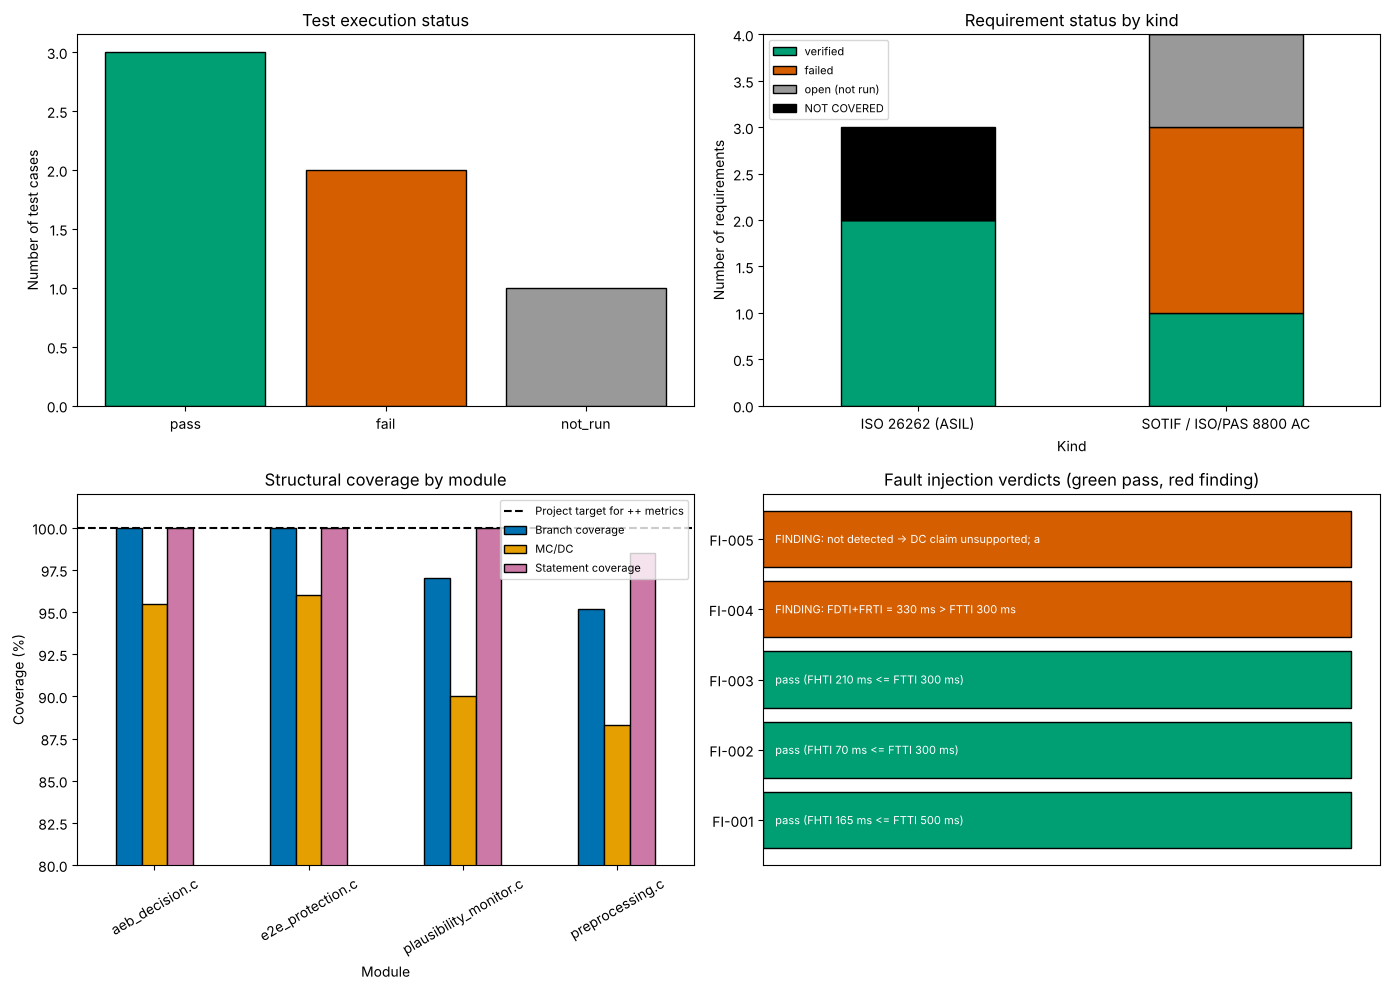

--- V&V dashboard (text summary) ---
  Tests: 3 passed, 2 failed, 1 not run
  ISO 26262 (ASIL): verified 2, NOT COVERED 1
  SOTIF / ISO/PAS 8800 AC: verified 1, failed 2, open (not run) 1
  Structural coverage gaps: 4
  Fault-injection findings: 2 of 5


In [11]:
def create_vv_dashboard(suite, cov, fi):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    okabe = {"pass": "#009E73", "fail": "#D55E00", "not_run": "#999999"}

    s = suite.coverage_summary()
    counts = {k: s[k] for k in ("pass", "fail", "not_run")}
    axes[0, 0].bar(list(counts), list(counts.values()), color=[okabe[k] for k in counts], edgecolor="black")
    axes[0, 0].set_ylabel("Number of test cases"); axes[0, 0].set_title("Test execution status")

    tr = suite.traceability_matrix()
    tr["Kind"] = np.where(tr.Integrity.str.startswith("ASIL"), "ISO 26262 (ASIL)", "SOTIF / ISO/PAS 8800 AC")
    status_order = ["verified", "failed", "open (not run)", "NOT COVERED"]
    colours = ["#009E73", "#D55E00", "#999999", "#000000"]
    tab = pd.crosstab(tr.Kind, tr.Status).reindex(columns=status_order, fill_value=0)
    tab.plot(kind="bar", stacked=True, ax=axes[0, 1], color=colours, edgecolor="black", rot=0)
    axes[0, 1].set_ylabel("Number of requirements"); axes[0, 1].set_title("Requirement status by kind")
    axes[0, 1].legend(fontsize=8)

    piv = cov.pivot(index="Module", columns="Metric", values="Achieved %")
    piv.plot(kind="bar", ax=axes[1, 0], color=["#0072B2", "#E69F00", "#CC79A7"], edgecolor="black", rot=30)
    axes[1, 0].axhline(PROJECT_TARGET, color="black", ls="--", label="Project target for ++ metrics")
    axes[1, 0].set_ylim(80, 102); axes[1, 0].set_ylabel("Coverage (%)")
    axes[1, 0].set_title("Structural coverage by module"); axes[1, 0].legend(fontsize=8)

    ok = fi.Verdict.str.startswith("pass")
    axes[1, 1].barh(fi.ID, np.ones(len(fi)), color=np.where(ok, "#009E73", "#D55E00"), edgecolor="black")
    for i, v in enumerate(fi.Verdict):
        axes[1, 1].text(0.02, i, v[:48], va="center", fontsize=8, color="white")
    axes[1, 1].set_xticks([]); axes[1, 1].set_title("Fault injection verdicts (green pass, red finding)")
    plt.tight_layout(); plt.show()
    return tab

tab = create_vv_dashboard(suite, cov, fi)
print("--- V&V dashboard (text summary) ---")
s = suite.coverage_summary()
print(f"  Tests: {s['pass']} passed, {s['fail']} failed, {s['not_run']} not run")
for kind, row in tab.iterrows():
    print(f"  {kind}: " + ", ".join(f"{k} {v}" for k, v in row.items() if v))
print(f"  Structural coverage gaps: {len(cov[cov.Verdict.str.startswith('GAP')])}")
print(f"  Fault-injection findings: {int((~fi.Verdict.str.startswith('pass')).sum())} of {len(fi)}")

## Key takeaways

1. **Three kinds of evidence:** verification (requirements fulfilled), safety validation (safety goals achieved at vehicle level, ISO 26262-4 clause 8) and confirmation measures (independent reviews, audit and assessment, ISO 26262-2).
2. **Method tables use ++ / + / o per ASIL, with no QM column.** Requirements-based and interface tests are ++ at every ASIL; fault injection and resource-usage evaluation are ++ only at ASIL D.
3. **Structural coverage has no fixed ISO percentage.** Measure the Table 9 metrics, set project targets, and analyse and justify gaps. MC/DC is highly recommended only at ASIL D.
4. **Test criteria must be at least as strict as the requirement.** Otherwise the test does not count as coverage.
5. **ML performance claims need statistics, not an ASIL.** "Recall ≥ 99 %" needs on the order of 300 independent, ODD-representative instances per scenario class with zero misses (95 % confidence).
6. **An undetected injected fault is a finding**, not a neutral result. Judge every mechanism against its FDTI and the FTTI of its safety goal.

## Self-assessment

1. What is the difference between verification and safety validation in ISO 26262? Where does the functional-safety audit fit?
2. Which structural coverage metrics are highly recommended at ASIL B and at ASIL D?
3. A test for "recall ≥ 99 %" accepts "recall ≥ 95 % in low light". Why can it not count as coverage, and how would you resolve it?
4. Your detector misses 0 of 250 pedestrians in an independent test set. Can you claim recall ≥ 99 % with 95 % confidence? How many instances would you need?
5. A fault-injection result reads "plausibility check passed (fault not severe enough)". How should it be reported?
6. Why is it wrong to assign an ASIL to "ECE < 0.05"?

<details>
<summary>Answers</summary>

1. Verification shows that a work product fulfils its specified requirements (at every level of the V). Safety validation shows at vehicle level that the safety goals are achieved and the safety concepts are appropriate. The functional-safety audit is a confirmation measure (ISO 26262-2) that judges the implementation of the safety process; it is neither verification nor validation.
2. ASIL B: statement and branch coverage (++); MC/DC is +. ASIL D: branch coverage and MC/DC (++); statement coverage is +.
3. Its acceptance criterion is weaker than the requirement. Either report it as a failure against the 99 % requirement, or specify (and justify in the SOTIF analysis) a separate degraded-mode requirement for low light and trace the test to that.
4. No. The 95 % upper bound on the miss rate is about 3/250 = 1.2 %, so the lower bound on recall is about 98.8 %. About 300 independent instances with zero misses are needed (more if misses occur), per scenario class.
5. As a finding: the injected fault escaped the safety mechanism. Analyse whether the fault is truly harmless (then justify it as a safe fault) or whether the mechanism's coverage is overestimated (then update the mechanism and the FMEDA).
6. ECE describes the nominal performance of an ML component. Achieving it is a matter of data, training and validation (ISO 21448 / ISO/PAS 8800), not of the fault-related process rigour that an ASIL grades.
</details>

## References

1. ISO 26262-2:2018, -4:2018, -6:2018 and -8:2018, *Road vehicles: Functional safety*. Geneva: ISO.
2. ISO 21448:2022, *Road vehicles: Safety of the intended functionality*. Geneva: ISO.
3. ISO/PAS 8800:2024, *Road vehicles: Safety and artificial intelligence*. Geneva: ISO. https://www.iso.org/standard/83303.html
4. RTCA DO-178C (2011), *Software Considerations in Airborne Systems and Equipment Certification* (origin of the MC/DC criterion).
5. Hayhurst, K. J., Veerhusen, D. S., Chilenski, J. J., Rierson, L. K. (2001). *A Practical Tutorial on Modified Condition/Decision Coverage*. NASA/TM-2001-210876.
6. Hanley, J. A., Lippman-Hand, A. (1983). If nothing goes wrong, is everything all right? Interpreting zero numerators. *JAMA*, 249(13), 1743–1745. https://doi.org/10.1001/jama.1983.03330370053031
7. Kalra, N., Paddock, S. M. (2016). *Driving to Safety*. RAND Corporation, RR-1478. https://www.rand.org/pubs/research_reports/RR1478.html
8. Patel, M., Jung, R. (2024). Simulation-Based Performance Evaluation of 3D Object Detection Methods with Deep Learning for a LiDAR Point Cloud Dataset in a SOTIF-related Use Case. *VEHITS 2024*. https://doi.org/10.5220/0012707300003702

---
**Navigation:** ← [04 Fault tree analysis](04_fault_tree_analysis.ipynb) · [Module index](README.md) · [Module 04: SOTIF (ISO 21448)](../04_SOTIF_ISO21448/README.md) →